<a href="https://colab.research.google.com/github/SMOULD07/-CLIP_with_medical_images/blob/main/Copie_de_TP_Distillation_M2VMI_Bilal_DELIKAYA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# TP Distillation de connaissances sur CIFAR10

Objectif :Étudier comment un réseau enseignant (teacher) peut guider un réseau élève (student) plus léger pour la classification d'images. Nous comparons d'abord ResNet50 et ResNet18, puis des CNN conçus sur mesure.

## 0. Préparation des données
Le jeu CIFAR-10 est partagé en 45 000 images d'entraînement, 5 000 de validation et 10 000 de test. Les images sont redimensionnées en 128 × 128 pour les expériences utilisant les modèles ResNet pré-entraînés sur ImageNet.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, time, copy
import numpy as np

device = 'cuda'
torch.manual_seed(0)
np.random.seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

!pip install -q datasets
from datasets import load_dataset

# telechargement de CIFAR10 depuis Hugging Face
ds = load_dataset('uoft-cs/cifar10')

def hf_to_tensor(split):
    x = np.stack([np.array(im) for im in split['img']])
    y = np.array(split['label'])
    return torch.tensor(x).permute(0, 3, 1, 2).contiguous(), torch.tensor(y)

x_all, y_all = hf_to_tensor(ds['train'])
x_test, y_test = hf_to_tensor(ds['test'])

# split train / val : 45000 / 5000
perm = torch.randperm(50000)
idx_tr, idx_val = perm[:45000], perm[45000:]
x_tr, y_tr = x_all[idx_tr].to(device), y_all[idx_tr].to(device)
x_val, y_val = x_all[idx_val].to(device), y_all[idx_val].to(device)
x_te, y_te = x_test.to(device), y_test.to(device)
print(x_tr.shape, x_val.shape, x_te.shape)

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
SIZE = 128

def prep(xb, train=False):
    xb = xb.float() / 255
    if train:
        # flip horizontal aleatoire
        flip = torch.rand(xb.size(0), device=device) < 0.5
        xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
        # random crop avec padding
        xb = F.pad(xb, (4, 4, 4, 4), mode='reflect')
        i, j = np.random.randint(0, 9, 2)
        xb = xb[:, :, i:i+32, j:j+32]
    xb = F.interpolate(xb, size=SIZE, mode='bilinear', align_corners=False)
    return (xb - mean) / std

def batches(x, y, bs, shuffle):
    n = x.size(0)
    idx = torch.randperm(n, device=device) if shuffle else torch.arange(n, device=device)
    for k in range(0, n, bs):
        b = idx[k:k+bs]
        yield prep(x[b], train=shuffle), y[b]

xb, yb = next(batches(x_tr, y_tr, 128, True))
print(xb.shape, yb[:10])

2.14.1+cu130 NVIDIA L4


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
torch.Size([128, 3, 128, 128]) tensor([9, 3, 7, 6, 3, 6, 0, 4, 3, 2], device='cuda:0')


## 1. Fonctions utilitaires


In [ ]:
from torchvision.models import resnet50, resnet18, ResNet50_Weights, ResNet18_Weights
from torch.utils.flop_counter import FlopCounterMode
import matplotlib.pyplot as plt

def get_resnet(name, pretrained):
    if name == 'resnet50':
        m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    else:
        m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m.to(device).to(memory_format=torch.channels_last)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def count_flops(model):
    model.eval()
    x = torch.randn(1, 3, SIZE, SIZE, device=device)
    with FlopCounterMode(display=False) as fc:
        with torch.no_grad():
            model(x)
    return fc.get_total_flops() / 1e9

@torch.no_grad()
def evaluate(model, x, y, bs=500):
    model.eval()
    correct, loss = 0, 0
    for xb, yb in batches(x, y, bs, False):
        with torch.autocast('cuda', dtype=torch.bfloat16):
            out = model(xb)
        loss += F.cross_entropy(out.float(), yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss / len(y), 100 * correct / len(y)

@torch.no_grad()
def inference_speed(model, n=5000, bs=250):
    model.eval()
    xs = [prep(x_te[k:k+bs]) for k in range(0, n, bs)]
    with torch.autocast('cuda', dtype=torch.bfloat16):
        for xb in xs[:3]:
            model(xb)
        torch.cuda.synchronize()
        t0 = time.time()
        for xb in xs:
            model(xb)
        torch.cuda.synchronize()
    total = time.time() - t0
    return 1000 * total / n, n / total

def train_model(model, epochs, lr, wd=5e-4, bs=256):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                          weight_decay=wd, nesterov=True)
    steps = epochs * ((x_tr.size(0) + bs - 1) // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_acc, best_state = 0, None
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot, n = 0, 0
        for xb, yb in batches(x_tr, y_tr, bs, True):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                out = model(xb)
            loss = F.cross_entropy(out.float(), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            tot += loss.detach() * xb.size(0)
            n += xb.size(0)
        vl, va = evaluate(model, x_val, y_val)
        hist['train_loss'].append((tot / n).item())
        hist['val_loss'].append(vl)
        hist['val_acc'].append(va)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"epoch {ep+1}/{epochs} | train loss {hist['train_loss'][-1]:.3f} | val loss {vl:.3f} | val acc {va:.2f}")
    model.load_state_dict(best_state)
    hist['time'] = time.time() - t0
    return hist

results = {}

def log_result(name, model, hist):
    _, test_acc = evaluate(model, x_te, y_te)
    ms, fps = inference_speed(model)
    p = count_params(model)
    results[name] = dict(test_acc=test_acc, val_acc=max(hist['val_acc']), params_M=p / 1e6,
                         size_MB=p * 4 / 1e6, gflops=count_flops(model),
                         ms_per_img=ms, fps=fps, train_time_s=hist['time'])
    print(name, {k: round(v, 3) for k, v in results[name].items()})

def plot_hist(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    ax[0].plot(hist['train_loss'], label='train')
    ax[0].plot(hist['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend()
    ax[1].plot(hist['val_acc'])
    ax[1].set_title('Accuracy validation (%)')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 2. Entraînement de l'enseignant (ResNet50)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 239MB/s]


Paramètres du prof : 23528522
epoch 1/10 | train loss 0.722 | val loss 0.199 | val acc 93.36
epoch 2/10 | train loss 0.147 | val loss 0.123 | val acc 95.98
epoch 3/10 | train loss 0.094 | val loss 0.110 | val acc 96.36
epoch 4/10 | train loss 0.066 | val loss 0.103 | val acc 96.70
epoch 5/10 | train loss 0.045 | val loss 0.099 | val acc 96.84
epoch 6/10 | train loss 0.033 | val loss 0.093 | val acc 97.12
epoch 7/10 | train loss 0.023 | val loss 0.085 | val acc 97.42
epoch 8/10 | train loss 0.016 | val loss 0.085 | val acc 97.54
epoch 9/10 | train loss 0.014 | val loss 0.083 | val acc 97.66
epoch 10/10 | train loss 0.012 | val loss 0.084 | val acc 97.54


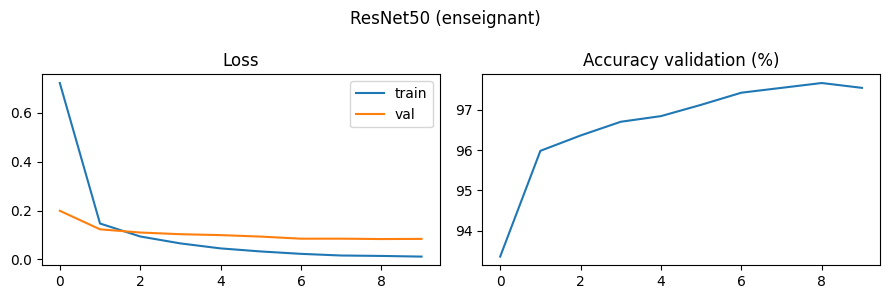

Prof ResNet50 {'test_acc': 97.16, 'val_acc': 97.66, 'params_M': 23.529, 'size_MB': 94.114, 'gflops': 2.669, 'ms_per_img': 0.214, 'fps': 4676.502, 'train_time_s': 329.83}


In [ ]:
teacher = get_resnet('resnet50', pretrained=True)
print("Paramètres du prof :", count_params(teacher))

hist_t = train_model(teacher, epochs=10, lr=0.02)
plot_hist(hist_t, 'ResNet50 (enseignant)')
log_result('Prof ResNet50', teacher, hist_t)

torch.save(teacher.state_dict(), 'teacher_resnet50.pt')

## 3. Stratégie 1 : élève pré-entraîné sur ImageNet

### 3.1 Élève seul (sans distillation)
ResNet18 pré-entraîné, fine-tuné sur CIFAR10 avec la même procédure que l'enseignant. Ce modèle sert de référence pour mesurer l'apport de la distillation.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 219MB/s]


Paramètres de l'élève : 11181642
epoch 1/10 | train loss 0.683 | val loss 0.254 | val acc 91.48
epoch 2/10 | train loss 0.229 | val loss 0.265 | val acc 90.86
epoch 3/10 | train loss 0.163 | val loss 0.183 | val acc 94.06
epoch 4/10 | train loss 0.123 | val loss 0.187 | val acc 93.62
epoch 5/10 | train loss 0.095 | val loss 0.176 | val acc 94.24
epoch 6/10 | train loss 0.073 | val loss 0.150 | val acc 95.24
epoch 7/10 | train loss 0.052 | val loss 0.144 | val acc 95.34
epoch 8/10 | train loss 0.039 | val loss 0.130 | val acc 96.20
epoch 9/10 | train loss 0.026 | val loss 0.125 | val acc 96.30
epoch 10/10 | train loss 0.022 | val loss 0.122 | val acc 96.34


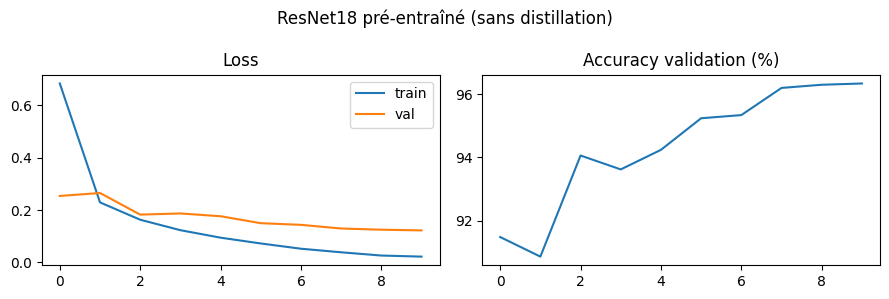

S1 ResNet18 seul {'test_acc': 95.31, 'val_acc': 96.34, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.057, 'fps': 17660.094, 'train_time_s': 93.319}


In [ ]:
hists = {'Prof ResNet50': hist_t}

student_pre = get_resnet('resnet18', pretrained=True)
print("Paramètres de l'élève :", count_params(student_pre))

h = train_model(student_pre, epochs=10, lr=0.02)
hists['S1 ResNet18 seul'] = h
plot_hist(h, 'ResNet18 pré-entraîné (sans distillation)')
log_result('S1 ResNet18 seul', student_pre, h)

### 3.2 Fonction de distillation
L'enseignant est figé en mode évaluation (sans calcul de gradient). L'élève est entraîné selon une fonction de perte combinant la cross-entropy (CE) sur les vraies étiquettes, la divergence KL sur les logits adoucis par une température $T$, et la distance (MSE) entre les feature maps finales — après projection des 512 canaux de l'élève vers les 2048 de l'enseignant via une convolution 1×1

Loss totale : (1 - alpha) CE + alpha T² KL + beta Dist(features)

In [ ]:
for p in teacher.parameters():
    p.requires_grad = False
teacher.eval()

def forward_feats(model, x):
    # renvoie les scores et la feature map de la derniere couche conv
    x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
    x = model.layer3(model.layer2(model.layer1(x)))
    f = model.layer4(x)
    out = model.fc(torch.flatten(model.avgpool(f), 1))
    return out, f

# distances possibles entre feature maps
def d_mse(s, t): return F.mse_loss(s, t)
def d_l1(s, t): return F.l1_loss(s, t)
def d_cos(s, t): return (1 - F.cosine_similarity(s, t, dim=1)).mean()
DISTS = {'mse': d_mse, 'l1': d_l1, 'cos': d_cos}

def train_kd(student, teacher, epochs, lr, alpha=0.5, T=4.0, use_feat=False,
             beta=1.0, dist='mse', wd=5e-4, bs=256):
    dist_fn = DISTS[dist]
    params = list(student.parameters())
    reg = None
    if use_feat:
        reg = nn.Conv2d(student.fc.in_features, teacher.fc.in_features, 1).to(device)
        reg = reg.to(memory_format=torch.channels_last)
        params += list(reg.parameters())
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    steps = epochs * ((x_tr.size(0) + bs - 1) // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_acc, best_state = 0, None
    t0 = time.time()
    for ep in range(epochs):
        student.train()
        tot, n = 0, 0
        for xb, yb in batches(x_tr, y_tr, bs, True):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                with torch.no_grad():
                    t_out, t_f = forward_feats(teacher, xb)
                s_out, s_f = forward_feats(student, xb)
                if use_feat:
                    s_f = reg(s_f)
            s_out, t_out = s_out.float(), t_out.float()
            ce = F.cross_entropy(s_out, yb)
            kd = F.kl_div(F.log_softmax(s_out / T, 1), F.softmax(t_out / T, 1),
                          reduction='batchmean') * T * T
            loss = (1 - alpha) * ce + alpha * kd
            if use_feat:
                loss = loss + beta * dist_fn(s_f.float(), t_f.float())
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            tot += loss.detach() * xb.size(0)
            n += xb.size(0)
        vl, va = evaluate(student, x_val, y_val)
        hist['train_loss'].append((tot / n).item())
        hist['val_loss'].append(vl)
        hist['val_acc'].append(va)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(student.state_dict())
        print(f"epoch {ep+1}/{epochs} | train loss {hist['train_loss'][-1]:.3f} | val loss {vl:.3f} | val acc {va:.2f}")
    student.load_state_dict(best_state)
    hist['time'] = time.time() - t0
    return hist

### 3.3 Distillation au niveau des scores


### 3.4 Distillation au niveau des scores et des feature maps


In [ ]:
import pandas as pd

# 3.3 scores seulement
s1_kd = get_resnet('resnet18', pretrained=True)
h = train_kd(s1_kd, teacher, epochs=10, lr=0.02, use_feat=False)
hists['S1 KD scores'] = h
log_result('S1 KD scores', s1_kd, h)

# 3.4 scores + feature maps
s1_kdf = get_resnet('resnet18', pretrained=True)
h = train_kd(s1_kdf, teacher, epochs=10, lr=0.02, use_feat=True, dist='mse')
hists['S1 KD scores+feat'] = h
log_result('S1 KD scores+feat', s1_kdf, h)

pd.DataFrame(results).T.round(2)

epoch 1/10 | train loss 2.784 | val loss 0.350 | val acc 89.76
epoch 2/10 | train loss 0.996 | val loss 0.316 | val acc 91.82
epoch 3/10 | train loss 0.729 | val loss 0.291 | val acc 92.66
epoch 4/10 | train loss 0.584 | val loss 0.244 | val acc 93.72
epoch 5/10 | train loss 0.497 | val loss 0.191 | val acc 94.76
epoch 6/10 | train loss 0.412 | val loss 0.180 | val acc 95.28
epoch 7/10 | train loss 0.340 | val loss 0.147 | val acc 95.92
epoch 8/10 | train loss 0.287 | val loss 0.134 | val acc 96.34
epoch 9/10 | train loss 0.258 | val loss 0.132 | val acc 96.44
epoch 10/10 | train loss 0.239 | val loss 0.131 | val acc 96.40
S1 KD scores {'test_acc': 96.33, 'val_acc': 96.44, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17764.511, 'train_time_s': 190.317}
epoch 1/10 | train loss 4.499 | val loss 0.379 | val acc 89.94
epoch 2/10 | train loss 2.244 | val loss 0.430 | val acc 89.82
epoch 3/10 | train loss 1.853 | val loss 0.243 | val acc 93.42
epoch 4/1

,test_acc,val_acc,params_M,size_MB,gflops,ms_per_img,fps,train_time_s
Prof ResNet50,97.16,97.66,23.53,94.11,2.67,0.21,4676.50,329.83
S1 ResNet18 seul,95.31,96.34,11.18,44.73,1.18,0.06,17660.09,93.32
S1 KD scores,96.33,96.44,11.18,44.73,1.18,0.06,17764.51,190.32
S1 KD scores+feat,96.03,96.56,11.18,44.73,1.18,0.06,17820.39,194.59


## 4. Stratégie 2 : élève non pré-entraîné

### 4.1 Élève seul (from scratch)
ResNet18 initialisé aléatoirement et entraîné sur CIFAR10. Le learning rate est plus élevé que pour le modèle pré-entraîné (0.1 au lieu de 0.02).

epoch 1/10 | train loss 1.712 | val loss 1.563 | val acc 44.90
epoch 2/10 | train loss 1.154 | val loss 1.041 | val acc 64.30
epoch 3/10 | train loss 0.852 | val loss 0.816 | val acc 71.72
epoch 4/10 | train loss 0.697 | val loss 0.774 | val acc 74.18
epoch 5/10 | train loss 0.605 | val loss 0.624 | val acc 78.66
epoch 6/10 | train loss 0.515 | val loss 0.627 | val acc 78.88
epoch 7/10 | train loss 0.452 | val loss 0.473 | val acc 83.68
epoch 8/10 | train loss 0.384 | val loss 0.429 | val acc 85.38
epoch 9/10 | train loss 0.310 | val loss 0.384 | val acc 86.82
epoch 10/10 | train loss 0.261 | val loss 0.352 | val acc 87.82


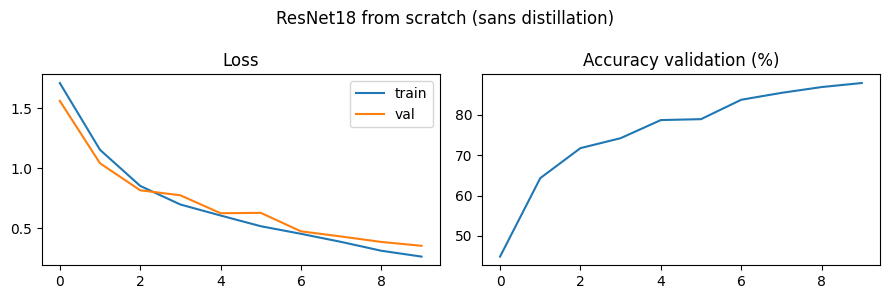

S2 ResNet18 seul {'test_acc': 88.04, 'val_acc': 87.82, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17721.473, 'train_time_s': 93.455}


In [ ]:
student_scr = get_resnet('resnet18', pretrained=False)
h = train_model(student_scr, epochs=10, lr=0.1)
hists['S2 ResNet18 seul'] = h
plot_hist(h, 'ResNet18 from scratch (sans distillation)')
log_result('S2 ResNet18 seul', student_scr, h)

### 4.2 Distillation au niveau des scores
### 4.3 Distillation au niveau des scores et des feature maps


In [ ]:
# 4.2 scores seulement
s2_kd = get_resnet('resnet18', pretrained=False)
h = train_kd(s2_kd, teacher, epochs=10, lr=0.1, use_feat=False)
hists['S2 KD scores'] = h
log_result('S2 KD scores', s2_kd, h)

# 4.3 scores + feature maps
s2_kdf = get_resnet('resnet18', pretrained=False)
h = train_kd(s2_kdf, teacher, epochs=10, lr=0.1, use_feat=True, dist='mse')
hists['S2 KD scores+feat'] = h
log_result('S2 KD scores+feat', s2_kdf, h)

epoch 1/10 | train loss 7.231 | val loss 2.147 | val acc 52.36
epoch 2/10 | train loss 4.659 | val loss 1.444 | val acc 66.18
epoch 3/10 | train loss 3.271 | val loss 1.021 | val acc 76.86
epoch 4/10 | train loss 2.685 | val loss 0.852 | val acc 80.16
epoch 5/10 | train loss 2.219 | val loss 0.875 | val acc 81.54
epoch 6/10 | train loss 1.921 | val loss 0.679 | val acc 84.14
epoch 7/10 | train loss 1.625 | val loss 0.622 | val acc 85.90
epoch 8/10 | train loss 1.344 | val loss 0.541 | val acc 87.52
epoch 9/10 | train loss 1.087 | val loss 0.445 | val acc 89.86
epoch 10/10 | train loss 0.903 | val loss 0.412 | val acc 90.06
S2 KD scores {'test_acc': 90.25, 'val_acc': 90.06, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17785.467, 'train_time_s': 190.575}
epoch 1/10 | train loss 8.732 | val loss 3.174 | val acc 47.58
epoch 2/10 | train loss 5.870 | val loss 2.049 | val acc 57.98
epoch 3/10 | train loss 4.502 | val loss 1.540 | val acc 67.36
epoch 4/1

## 5. Comparaison des stratégies 1 et 2


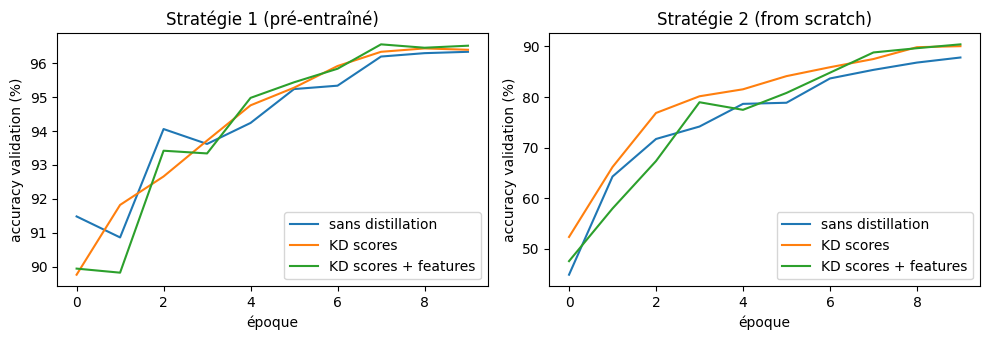

,test_acc,val_acc,params_M,size_MB,gflops,ms_per_img,fps,train_time_s
Prof ResNet50,97.16,97.66,23.53,94.11,2.67,0.21,4676.50,329.83
S1 ResNet18 seul,95.31,96.34,11.18,44.73,1.18,0.06,17660.09,93.32
S1 KD scores,96.33,96.44,11.18,44.73,1.18,0.06,17764.51,190.32
S1 KD scores+feat,96.03,96.56,11.18,44.73,1.18,0.06,17820.39,194.59
S2 ResNet18 seul,88.04,87.82,11.18,44.73,1.18,0.06,17721.47,93.45
S2 KD scores,90.25,90.06,11.18,44.73,1.18,0.06,17785.47,190.58
S2 KD scores+feat,90.09,90.42,11.18,44.73,1.18,0.06,17749.52,194.74


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
for a, pre, titre in [(ax[0], 'S1', 'Stratégie 1 (pré-entraîné)'),
                      (ax[1], 'S2', 'Stratégie 2 (from scratch)')]:
    for suffix, lab in [('ResNet18 seul', 'sans distillation'),
                        ('KD scores', 'KD scores'),
                        ('KD scores+feat', 'KD scores + features')]:
        a.plot(hists[f'{pre} {suffix}']['val_acc'], label=lab)
    a.set_title(titre)
    a.set_xlabel('époque')
    a.set_ylabel('accuracy validation (%)')
    a.legend()
plt.tight_layout()
plt.savefig('comparaison_strategies.png', dpi=150)
plt.show()

pd.DataFrame(results).T.round(2)

## 6. Comparaison de distances entre feature maps


In [ ]:
essais = [('S1 KD feat L1', 'l1', 1.0),
          ('S1 KD feat cosinus', 'cos', 1.0),
          ('S1 KD feat MSE beta=0.1', 'mse', 0.1)]

for nom, d, b in essais:
    m = get_resnet('resnet18', pretrained=True)
    h = train_kd(m, teacher, epochs=10, lr=0.02, use_feat=True, dist=d, beta=b)
    hists[nom] = h
    log_result(nom, m, h)

noms = ['S1 KD scores', 'S1 KD scores+feat', 'S1 KD feat L1',
        'S1 KD feat cosinus', 'S1 KD feat MSE beta=0.1']
pd.DataFrame(results).T.loc[noms, ['test_acc', 'val_acc']].round(2)

epoch 1/10 | train loss 3.523 | val loss 0.405 | val acc 89.26
epoch 2/10 | train loss 1.432 | val loss 0.311 | val acc 91.90
epoch 3/10 | train loss 1.089 | val loss 0.286 | val acc 92.84
epoch 4/10 | train loss 0.925 | val loss 0.260 | val acc 93.34
epoch 5/10 | train loss 0.800 | val loss 0.188 | val acc 95.18
epoch 6/10 | train loss 0.707 | val loss 0.182 | val acc 95.68
epoch 7/10 | train loss 0.634 | val loss 0.153 | val acc 95.92
epoch 8/10 | train loss 0.569 | val loss 0.142 | val acc 96.40
epoch 9/10 | train loss 0.526 | val loss 0.144 | val acc 96.26
epoch 10/10 | train loss 0.510 | val loss 0.144 | val acc 96.20
S1 KD feat L1 {'test_acc': 95.61, 'val_acc': 96.4, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17776.286, 'train_time_s': 195.326}
epoch 1/10 | train loss 3.721 | val loss 0.387 | val acc 90.10
epoch 2/10 | train loss 1.801 | val loss 0.363 | val acc 90.84
epoch 3/10 | train loss 1.507 | val loss 0.244 | val acc 93.38
epoch 4/1

,test_acc,val_acc
S1 KD scores,96.33,96.44
S1 KD scores+feat,96.03,96.56
S1 KD feat L1,95.61,96.40
S1 KD feat cosinus,95.97,96.54
S1 KD feat MSE beta=0.1,95.91,96.62


## 7. Réseaux construits sur mesure

### 7.1 Enseignant sur mesure
CNN de type VGG avec quatre étages de deux convolutions (largeurs 64, 128, 256, 512), batch normalization et max pooling entre les étages, suivi d'un pooling global et d'une couche linéaire. Les images sont gardées en 32x32 et le réseau est entraîné from scratch.

Paramètres du prof maison : 4692426


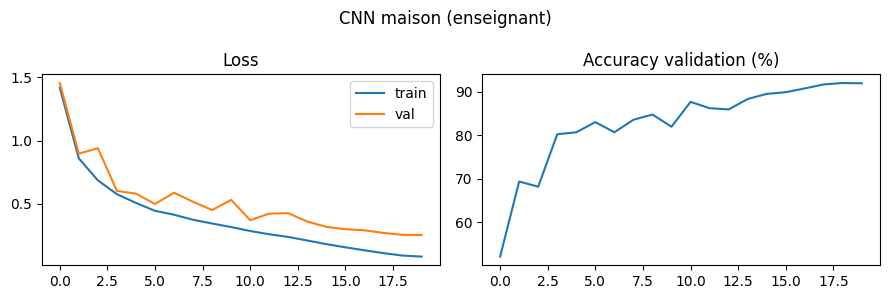

C prof (w=64) {'test_acc': 91.26, 'val_acc': 92.06, 'params_M': 4.692, 'size_MB': 18.77, 'gflops': 0.419, 'ms_per_img': 0.014, 'fps': 72863.571, 'train_time_s': 50.751}


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): Ma

In [ ]:
import io, contextlib

SIZE = 32  # images gardees en 32x32 pour les reseaux maison

def block(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

class CustomCNN(nn.Module):
    def __init__(self, w=64, n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for i, c in enumerate([w, 2*w, 4*w, 8*w]):
            layers += block(cin, c) + block(c, c)
            if i < 3:
                layers.append(nn.MaxPool2d(2))
            cin = c
        self.features = nn.Sequential(*layers)
        self.fc = nn.Linear(8 * w, n_classes)

    def get_feats(self, x):
        f = self.features(x)
        out = self.fc(torch.flatten(F.adaptive_avg_pool2d(f, 1), 1))
        return out, f

    def forward(self, x):
        return self.get_feats(x)[0]

def make_cnn(w):
    return CustomCNN(w).to(device).to(memory_format=torch.channels_last)

# forward_feats gere maintenant les ResNet et les CNN maison
def forward_feats(model, x):
    if hasattr(model, 'get_feats'):
        return model.get_feats(x)
    x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
    x = model.layer3(model.layer2(model.layer1(x)))
    f = model.layer4(x)
    out = model.fc(torch.flatten(model.avgpool(f), 1))
    return out, f

def quiet(fn, *a, **k):
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*a, **k)

EPOCHS_C, LR_C = 20, 0.05

teacher_c = make_cnn(64)
print("Paramètres du prof maison :", count_params(teacher_c))
h = quiet(train_model, teacher_c, EPOCHS_C, LR_C)
hists['C prof (w=64)'] = h
plot_hist(h, 'CNN maison (enseignant)')
log_result('C prof (w=64)', teacher_c, h)

for p in teacher_c.parameters():
    p.requires_grad = False
teacher_c.eval()

### 7.2 Élèves compressés
Même architecture avec des largeurs divisées par 2, 3 et 4 (32, 21 et 16 canaux au premier étage). Pour chaque taille, trois entraînements sont comparés : sans distillation, avec distillation des scores, et avec distillation des scores et des feature maps (MSE).

C /2 seul {'test_acc': 89.67, 'val_acc': 90.0, 'params_M': 1.176, 'size_MB': 4.703, 'gflops': 0.106, 'ms_per_img': 0.005, 'fps': 192024.026, 'train_time_s': 21.159}
C /2 KD scores {'test_acc': 90.54, 'val_acc': 91.04, 'params_M': 1.176, 'size_MB': 4.703, 'gflops': 0.106, 'ms_per_img': 0.005, 'fps': 188296.476, 'train_time_s': 31.369}
C /2 KD scores+feat {'test_acc': 90.15, 'val_acc': 90.7, 'params_M': 1.176, 'size_MB': 4.703, 'gflops': 0.106, 'ms_per_img': 0.005, 'fps': 193920.385, 'train_time_s': 32.828}
C /3 seul {'test_acc': 87.81, 'val_acc': 88.52, 'params_M': 0.508, 'size_MB': 2.03, 'gflops': 0.046, 'ms_per_img': 0.006, 'fps': 154174.012, 'train_time_s': 23.155}
C /3 KD scores {'test_acc': 88.84, 'val_acc': 90.04, 'params_M': 0.508, 'size_MB': 2.03, 'gflops': 0.046, 'ms_per_img': 0.007, 'fps': 152919.404, 'train_time_s': 32.665}
C /3 KD scores+feat {'test_acc': 89.08, 'val_acc': 89.96, 'params_M': 0.508, 'size_MB': 2.03, 'gflops': 0.046, 'ms_per_img': 0.006, 'fps': 154473.818, 'tr

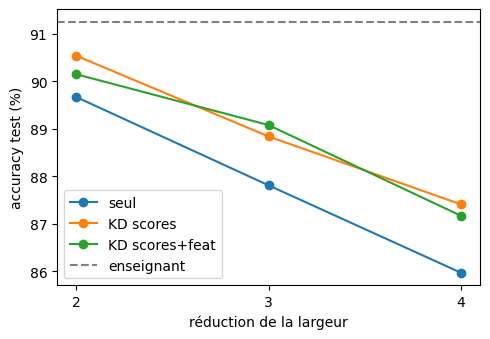

,test_acc,val_acc,params_M,size_MB,gflops,ms_per_img,fps,train_time_s
C prof (w=64),91.26,92.06,4.69,18.77,0.42,0.01,72863.57,50.75
C /2 seul,89.67,90.00,1.18,4.70,0.11,0.01,192024.03,21.16
C /2 KD scores,90.54,91.04,1.18,4.70,0.11,0.01,188296.48,31.37
C /2 KD scores+feat,90.15,90.70,1.18,4.70,0.11,0.01,193920.38,32.83
C /3 seul,87.81,88.52,0.51,2.03,0.05,0.01,154174.01,23.16
C /3 KD scores,88.84,90.04,0.51,2.03,0.05,0.01,152919.40,32.66
C /3 KD scores+feat,89.08,89.96,0.51,2.03,0.05,0.01,154473.82,34.18
C /4 seul,85.97,86.90,0.30,1.18,0.03,0.01,195474.86,20.44
C /4 KD scores,87.41,87.52,0.30,1.18,0.03,0.01,192508.77,27.90
C /4 KD scores+feat,87.17,88.50,0.30,1.18,0.03,0.01,195024.04,30.12


In [ ]:
for d in [2, 3, 4]:
    w = 64 // d
    for mode in ['seul', 'KD scores', 'KD scores+feat']:
        s = make_cnn(w)
        nom = f'C /{d} {mode}'
        if mode == 'seul':
            h = quiet(train_model, s, EPOCHS_C, LR_C)
        else:
            h = quiet(train_kd, s, teacher_c, EPOCHS_C, LR_C,
                      use_feat=(mode == 'KD scores+feat'))
        hists[nom] = h
        log_result(nom, s, h)

res = pd.DataFrame(results).T
fig, ax = plt.subplots(figsize=(5, 3.5))
for mode in ['seul', 'KD scores', 'KD scores+feat']:
    ax.plot([2, 3, 4], [res.loc[f'C /{d} {mode}', 'test_acc'] for d in [2, 3, 4]],
            marker='o', label=mode)
ax.axhline(res.loc['C prof (w=64)', 'test_acc'], color='gray', ls='--', label='enseignant')
ax.set_xticks([2, 3, 4])
ax.set_xlabel('réduction de la largeur')
ax.set_ylabel('accuracy test (%)')
ax.legend()
plt.tight_layout()
plt.savefig('eleves_maison.png', dpi=150)
plt.show()

res.loc[[k for k in res.index if k.startswith('C ')]].round(2)

In [ ]:
SIZE = 128  # retour a la resolution utilisee avec ResNet50

def d_at(s, t):
    a_s = F.normalize(s.float().pow(2).mean(1).flatten(1), dim=1)
    a_t = F.normalize(t.float().pow(2).mean(1).flatten(1), dim=1)
    return (a_s - a_t).pow(2).mean()

def d_icc(s, t):
    # correlation entre canaux, ||AA'-BB'||^2 calculee avec des matrices HW x HW
    s = F.normalize(s.float().flatten(2), dim=2)
    t = F.normalize(t.float().flatten(2), dim=2)
    ss = torch.bmm(s.transpose(1, 2), s)
    tt = torch.bmm(t.transpose(1, 2), t)
    st = torch.bmm(s.transpose(1, 2), t)
    C = s.size(1)
    return ((ss**2).sum((1, 2)) + (tt**2).sum((1, 2)) - 2 * (st**2).sum((1, 2))).mean() / C**2

DISTS['at'] = d_at
DISTS['icc'] = d_icc

for nom, d, b in [('S1 KD feat AT', 'at', 100.0), ('S1 KD feat ICC', 'icc', 10.0)]:
    m = get_resnet('resnet18', pretrained=True)
    h = quiet(train_kd, m, teacher, 10, 0.02, use_feat=True, dist=d, beta=b)
    hists[nom] = h
    log_result(nom, m, h)

noms = ['S1 KD scores', 'S1 KD scores+feat', 'S1 KD feat L1', 'S1 KD feat cosinus',
        'S1 KD feat AT', 'S1 KD feat ICC']
pd.DataFrame(results).T.loc[noms, ['test_acc', 'val_acc']].round(2)

S1 KD feat AT {'test_acc': 96.29, 'val_acc': 96.84, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17771.571, 'train_time_s': 195.742}
S1 KD feat ICC {'test_acc': 95.85, 'val_acc': 96.32, 'params_M': 11.182, 'size_MB': 44.727, 'gflops': 1.184, 'ms_per_img': 0.056, 'fps': 17954.992, 'train_time_s': 202.735}


,test_acc,val_acc
S1 KD scores,96.33,96.44
S1 KD scores+feat,96.03,96.56
S1 KD feat L1,95.61,96.40
S1 KD feat cosinus,95.97,96.54
S1 KD feat AT,96.29,96.84
S1 KD feat ICC,95.85,96.32


In [ ]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
SIZE = 128

class MobileNetS(nn.Module):
    def __init__(self):
        super().__init__()
        m = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V2)
        self.features = m.features
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(1280, 10)

    def get_feats(self, x):
        f = self.features(x)
        out = self.fc(self.drop(torch.flatten(F.adaptive_avg_pool2d(f, 1), 1)))
        return out, f

    def forward(self, x):
        return self.get_feats(x)[0]

def make_mb():
    return MobileNetS().to(device).to(memory_format=torch.channels_last)

for mode in ['seul', 'KD scores', 'KD scores+feat']:
    s = make_mb()
    nom = f'MB {mode}'
    if mode == 'seul':
        h = quiet(train_model, s, 10, 0.02)
    else:
        h = quiet(train_kd, s, teacher, 10, 0.02, use_feat=(mode == 'KD scores+feat'))
    hists[nom] = h
    log_result(nom, s, h)

pd.DataFrame(results).T.loc[[k for k in results if k.startswith('MB')],
                            ['test_acc', 'val_acc', 'params_M', 'gflops', 'fps']].round(2)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 64.8MB/s]


MB seul {'test_acc': 95.07, 'val_acc': 95.58, 'params_M': 2.237, 'size_MB': 8.947, 'gflops': 0.196, 'ms_per_img': 0.091, 'fps': 11048.9, 'train_time_s': 174.495}
MB KD scores {'test_acc': 95.98, 'val_acc': 96.1, 'params_M': 2.237, 'size_MB': 8.947, 'gflops': 0.196, 'ms_per_img': 0.09, 'fps': 11079.944, 'train_time_s': 261.952}
MB KD scores+feat {'test_acc': 95.79, 'val_acc': 96.16, 'params_M': 2.237, 'size_MB': 8.947, 'gflops': 0.196, 'ms_per_img': 0.091, 'fps': 11042.879, 'train_time_s': 267.147}


,test_acc,val_acc,params_M,gflops,fps
MB seul,95.07,95.58,2.24,0.2,11048.90
MB KD scores,95.98,96.10,2.24,0.2,11079.94
MB KD scores+feat,95.79,96.16,2.24,0.2,11042.88
